# **Humanitarian Crisis Message Classification**

## **Problem Definition**

### **Context**

During major disasters, humanitarian organizations may receive large volumes
of social-media messages containing information about urgent needs,
infrastructure damage, casualties, evacuations, rescue efforts, and other
crisis-related information.

Manually reviewing large volumes of messages can be time-consuming. An
automated classification system could help organize incoming information and
support responders in identifying relevant humanitarian information more
efficiently.

### **Objective**

The objective of this project is to develop a machine-learning system that
classifies disaster-related messages into humanitarian information categories.

The trained model will then be integrated into an interactive prototype that
allows a user to enter an incoming crisis message and receive a predicted
humanitarian category.

### **Key Questions**

1. What humanitarian categories are represented in the dataset?
2. Are the classes balanced across disaster events?
3. How should crisis-message text be prepared for machine learning?
4. How accurately can a baseline NLP model classify humanitarian messages?
5. Which categories are most commonly confused?
6. Does the model generalize across different disaster events?
7. Can the trained model be incorporated into a useful interactive prototype?

### **Problem Formulation**

This is a supervised multiclass text-classification problem. Each message is
associated with a humanitarian class label. Text features will be extracted
from the messages and used to train and evaluate machine-learning classifiers.

## **1. Environment Setup**

This notebook is developed in Google Colab. The core Python libraries required
for the initial data analysis and machine-learning workflow are pre-installed
in the Colab environment, so no additional package installation is required
at this stage.

## **2. Importing Libraries**

In [1]:
# Import necessary libraries

# File and directory handling
import os
import tarfile
from pathlib import Path

# Data manipulation
import numpy as np
import pandas as pd

# Data visualization
import matplotlib.pyplot as plt

# Machine learning - text feature extraction
from sklearn.feature_extraction.text import TfidfVectorizer

# Machine learning - classification
from sklearn.linear_model import LogisticRegression

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

## **3. Data Loading and Initial Inspection**

Before loading the disaster-event datasets into pandas, the downloaded archive
will first be inspected to understand its internal directory structure and
identify the available data files.

In [2]:
# Upload the raw HumAID dataset archive

from google.colab import files

uploaded = files.upload()

Saving HumAID_data_events_set1_47K.tar.gz to HumAID_data_events_set1_47K.tar.gz


In [3]:
# Check the files available in the Colab working directory

for file_name in os.listdir("/content"):
    print(file_name)

.config
HumAID_data_events_set1_47K.tar.gz
sample_data


In [4]:
# Define the path to the downloaded HumAID archive

archive_path = Path("/content/HumAID_data_events_set1_47K.tar.gz")

print("Archive path:", archive_path)
print("Archive exists:", archive_path.exists())

Archive path: /content/HumAID_data_events_set1_47K.tar.gz
Archive exists: True


### **Inspecting the Archive Contents**

The archive contains data collected from multiple disaster events. Before
extracting the files, the archive structure will be inspected to determine
the number, type, and organization of the files it contains.

In [5]:
# Inspect the contents of the TAR.GZ archive without extracting it

with tarfile.open(archive_path, mode="r:gz") as tar:
    archive_members = tar.getnames()

print(f"Number of items in archive: {len(archive_members)}")

# Display the first 20 items
for member in archive_members[:20]:
    print(member)

Number of items in archive: 59
events_set1
events_set1/._.DS_Store
events_set1/.DS_Store
events_set1/kaikoura_earthquake_2016
events_set1/hurricane_harvey_2017
events_set1/hurricane_maria_2017
events_set1/puebla_mexico_earthquake_2017
events_set1/hurricane_irma_2017
events_set1/ecuador_earthquake_2016
events_set1/cyclone_idai_2019
events_set1/canada_wildfires_2016
events_set1/._Licensing.txt
events_set1/Licensing.txt
events_set1/._Readme.txt
events_set1/Readme.txt
events_set1/italy_earthquake_aug_2016
events_set1/hurricane_matthew_2016
events_set1/srilanka_floods_2017
events_set1/srilanka_floods_2017/srilanka_floods_2017_train.tsv
events_set1/srilanka_floods_2017/srilanka_floods_2017_test.tsv


### **Extracting the Dataset**

The archive will now be extracted into a dedicated data directory. The original
archive will remain unchanged so that the raw downloaded data is preserved.

After extraction, Python will be used to identify the available TSV data files
automatically rather than relying on manual file selection.

In [6]:
# Create a directory for the extracted HumAID dataset

extract_dir = Path("/content/humaid_data")
extract_dir.mkdir(parents=True, exist_ok=True)

print("Extraction directory:", extract_dir)

Extraction directory: /content/humaid_data


In [7]:
# Extract the HumAID archive

with tarfile.open(archive_path, mode="r:gz") as tar:
    tar.extractall(path=extract_dir)

print("Dataset extracted successfully.")

Dataset extracted successfully.


/tmp/ipykernel_963/1982789816.py:4: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(path=extract_dir)


### **Identifying the Data Files**

The extracted dataset contains multiple disaster-event directories together
with documentation and system-generated metadata files. Only TSV files will
be identified for the subsequent data analysis.

In [8]:
# Find all TSV files within the extracted dataset

tsv_files = sorted(extract_dir.rglob("*.tsv"))

print(f"Number of TSV files found: {len(tsv_files)}")

for file_path in tsv_files:
    print(file_path)

Number of TSV files found: 39
/content/humaid_data/events_set1/canada_wildfires_2016/canada_wildfires_2016_dev.tsv
/content/humaid_data/events_set1/canada_wildfires_2016/canada_wildfires_2016_test.tsv
/content/humaid_data/events_set1/canada_wildfires_2016/canada_wildfires_2016_train.tsv
/content/humaid_data/events_set1/cyclone_idai_2019/cyclone_idai_2019_dev.tsv
/content/humaid_data/events_set1/cyclone_idai_2019/cyclone_idai_2019_test.tsv
/content/humaid_data/events_set1/cyclone_idai_2019/cyclone_idai_2019_train.tsv
/content/humaid_data/events_set1/ecuador_earthquake_2016/ecuador_earthquake_2016_dev.tsv
/content/humaid_data/events_set1/ecuador_earthquake_2016/ecuador_earthquake_2016_test.tsv
/content/humaid_data/events_set1/ecuador_earthquake_2016/ecuador_earthquake_2016_train.tsv
/content/humaid_data/events_set1/hurricane_harvey_2017/hurricane_harvey_2017_dev.tsv
/content/humaid_data/events_set1/hurricane_harvey_2017/hurricane_harvey_2017_test.tsv
/content/humaid_data/events_set1/hurr

In [9]:
# Load one TSV file to inspect its structure

sample_file = tsv_files[0]

sample_df = pd.read_csv(sample_file, sep="\t")

print("Sample file:")
print(sample_file)

print("\nShape:")
print(sample_df.shape)

print("\nColumn names:")
print(sample_df.columns.tolist())

sample_df.head()

Sample file:
/content/humaid_data/events_set1/canada_wildfires_2016/canada_wildfires_2016_dev.tsv

Shape:
(228, 3)

Column names:
['tweet_id', 'tweet_text', 'class_label']


,tweet_id,tweet_text,class_label
0,733360620339257344,.@GreenABEnergy How can @AirworksCanada assist...,rescue_volunteering_or_donation_effort
1,729520926795157504,RT @katvondawn: Thoughts &amp; prayers going t...,sympathy_and_support
2,730739571739271168,Glacier Farm Media pledges $50K in support for...,rescue_volunteering_or_donation_effort
3,733688875529293824,Beatton Airport Road wildfire in northern B.C....,infrastructure_and_utility_damage
4,733046257090957312,RT @dana_balsor: @InsuranceBureau will Insur. ...,other_relevant_information


### **Dataset Inventory**

Before combining the individual event datasets, an inventory will be created
to summarize the available files. For each file, the disaster event, dataset
split, number of messages, and number of class labels will be recorded.

This step helps verify the structure and consistency of the dataset before
proceeding with data preparation and modelling.

In [10]:
# Build an inventory of all TSV files

inventory_records = []

for file_path in tsv_files:

    # Load the current TSV file
    df = pd.read_csv(file_path, sep="\t")

    # Extract the filename without the .tsv extension
    file_stem = file_path.stem

    # Determine the dataset split from the filename
    if file_stem.endswith("_train"):
        split = "train"
        event = file_stem.removesuffix("_train")

    elif file_stem.endswith("_dev"):
        split = "dev"
        event = file_stem.removesuffix("_dev")

    elif file_stem.endswith("_test"):
        split = "test"
        event = file_stem.removesuffix("_test")

    else:
        split = "unknown"
        event = file_stem

    # Store information about the current file
    inventory_records.append({
        "event": event,
        "split": split,
        "rows": len(df),
        "columns": len(df.columns),
        "n_classes": df["class_label"].nunique(),
        "file_name": file_path.name
    })

# Convert the collected records into a DataFrame
inventory_df = pd.DataFrame(inventory_records)

inventory_df

,event,split,rows,columns,n_classes,file_name
0,canada_wildfires_2016,dev,228,3,8,canada_wildfires_2016_dev.tsv
1,canada_wildfires_2016,test,445,3,8,canada_wildfires_2016_test.tsv
2,canada_wildfires_2016,train,1569,3,8,canada_wildfires_2016_train.tsv
3,cyclone_idai_2019,dev,401,3,10,cyclone_idai_2019_dev.tsv
4,cyclone_idai_2019,test,779,3,10,cyclone_idai_2019_test.tsv
5,cyclone_idai_2019,train,2753,3,10,cyclone_idai_2019_train.tsv
6,ecuador_earthquake_2016,dev,159,3,8,ecuador_earthquake_2016_dev.tsv
7,ecuador_earthquake_2016,test,310,3,8,ecuador_earthquake_2016_test.tsv
8,ecuador_earthquake_2016,train,1094,3,8,ecuador_earthquake_2016_train.tsv
9,hurricane_harvey_2017,dev,929,3,9,hurricane_harvey_2017_dev.tsv


### **Inventory Summary**

The dataset inventory will now be summarized to verify the number of disaster
events, dataset splits, and total number of messages available.

In [11]:
# Summarize the dataset inventory

print("Number of disaster events:", inventory_df["event"].nunique())
print("Number of TSV files:", len(inventory_df))
print("Total number of messages:", inventory_df["rows"].sum())

print("\nFiles by split:")
print(inventory_df["split"].value_counts())

print("\nMessages by split:")
print(inventory_df.groupby("split")["rows"].sum())

Number of disaster events: 13
Number of TSV files: 39
Total number of messages: 43409

Files by split:
split
dev      13
test     13
train    13
Name: count, dtype: int64

Messages by split:
split
dev       4422
test      8606
train    30381
Name: rows, dtype: int64


In [12]:
# Compare the number of messages across disaster events and dataset splits

event_split_counts = inventory_df.pivot(
    index="event",
    columns="split",
    values="rows"
)

event_split_counts["total"] = event_split_counts.sum(axis=1)

event_split_counts.sort_values("total", ascending=False)

split,dev,test,train,total
event,,,,
hurricane_irma_2017,958,1862,6579,9399
hurricane_harvey_2017,929,1805,6378,9112
hurricane_maria_2017,742,1442,5094,7278
cyclone_idai_2019,401,779,2753,3933
canada_wildfires_2016,228,445,1569,2242
kaikoura_earthquake_2016,224,435,1536,2195
puebla_mexico_earthquake_2017,205,400,1410,2015
hurricane_matthew_2016,168,329,1157,1654
ecuador_earthquake_2016,159,310,1094,1563


## **4. Class Label Analysis**

Before preparing the data for modelling, the humanitarian class labels will be
examined across disaster events.

The analysis will determine:

- which humanitarian categories are present,
- how frequently each category occurs,
- whether the classes are imbalanced, and
- whether all categories are represented across all disaster events.

Understanding the target distribution is important for selecting appropriate
evaluation metrics and designing the modelling strategy.

In [13]:
# Identify all unique humanitarian class labels across the dataset

all_labels = set()

for file_path in tsv_files:
    df = pd.read_csv(file_path, sep="\t")
    all_labels.update(df["class_label"].dropna().unique())

all_labels = sorted(all_labels)

print(f"Number of unique class labels: {len(all_labels)}")

for label in all_labels:
    print(label)

Number of unique class labels: 10
caution_and_advice
displaced_people_and_evacuations
infrastructure_and_utility_damage
injured_or_dead_people
missing_or_found_people
not_humanitarian
other_relevant_information
requests_or_urgent_needs
rescue_volunteering_or_donation_effort
sympathy_and_support


### **Overall Class Distribution**

The frequency of each humanitarian category will now be calculated across all
available messages. This provides an initial assessment of class imbalance
within the complete dataset.

In [14]:
# Count class labels across all TSV files

label_counts = []

for file_path in tsv_files:
    df = pd.read_csv(file_path, sep="\t")
    label_counts.append(df["class_label"])

all_class_labels = pd.concat(label_counts, ignore_index=True)

class_distribution = all_class_labels.value_counts()

class_distribution

,count
class_label,
rescue_volunteering_or_donation_effort,12164
other_relevant_information,7644
infrastructure_and_utility_damage,6045
sympathy_and_support,5081
injured_or_dead_people,4236
caution_and_advice,2287
displaced_people_and_evacuations,2136
not_humanitarian,1986
requests_or_urgent_needs,1651


In [15]:
# Create a class distribution summary

class_distribution_df = class_distribution.reset_index()
class_distribution_df.columns = ["class_label", "count"]

class_distribution_df["percentage"] = (
    class_distribution_df["count"] / class_distribution_df["count"].sum() * 100
)

class_distribution_df

,class_label,count,percentage
0,rescue_volunteering_or_donation_effort,12164,28.021839
1,other_relevant_information,7644,17.609252
2,infrastructure_and_utility_damage,6045,13.925684
3,sympathy_and_support,5081,11.704946
4,injured_or_dead_people,4236,9.758345
5,caution_and_advice,2287,5.268493
6,displaced_people_and_evacuations,2136,4.920639
7,not_humanitarian,1986,4.575088
8,requests_or_urgent_needs,1651,3.803359
9,missing_or_found_people,179,0.412357


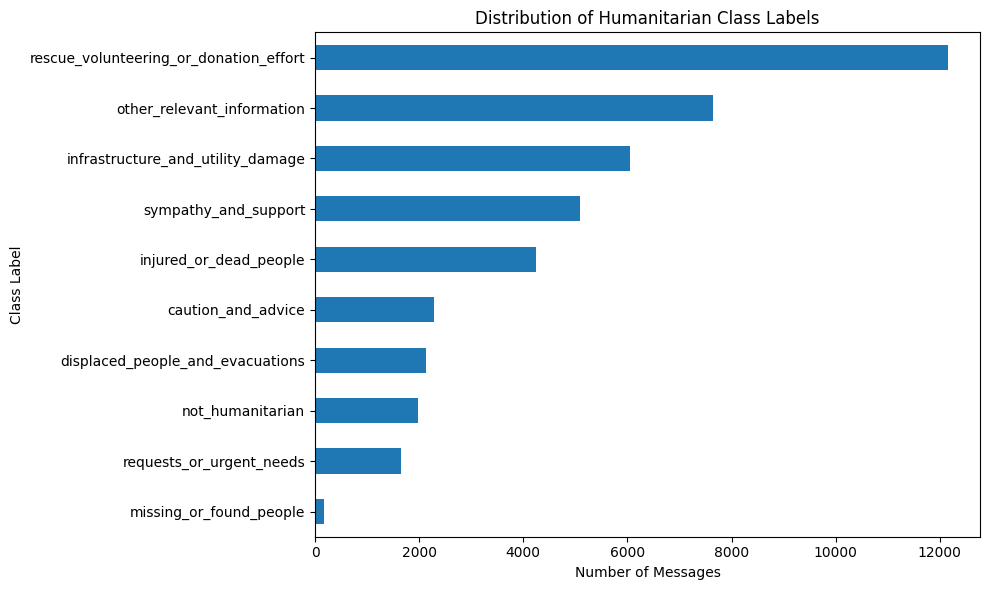

In [16]:
# Visualize the overall class distribution

plt.figure(figsize=(10, 6))

class_distribution.sort_values().plot(kind="barh")

plt.title("Distribution of Humanitarian Class Labels")
plt.xlabel("Number of Messages")
plt.ylabel("Class Label")
plt.tight_layout()

plt.show()

### **Class Distribution Across Disaster Events**

The overall class distribution is imbalanced, with substantial differences in
the number of messages assigned to each humanitarian category.

However, the overall distribution may conceal differences between individual
disaster events. The class composition of each event will therefore be examined
to determine whether humanitarian information categories are represented
consistently across disasters.

This analysis will help assess whether a model evaluated on randomly mixed
messages would adequately represent its ability to generalize to a new
disaster event.

In [17]:
# Combine all event datasets while preserving event and split information

dataframes = []

for file_path in tsv_files:

    # Load the current TSV file
    df = pd.read_csv(file_path, sep="\t")

    # Identify the event and original dataset split
    file_stem = file_path.stem

    if file_stem.endswith("_train"):
        split = "train"
        event = file_stem.removesuffix("_train")

    elif file_stem.endswith("_dev"):
        split = "dev"
        event = file_stem.removesuffix("_dev")

    elif file_stem.endswith("_test"):
        split = "test"
        event = file_stem.removesuffix("_test")

    else:
        split = "unknown"
        event = file_stem

    # Preserve the source event and split for every message
    df["event"] = event
    df["original_split"] = split

    dataframes.append(df)

# Combine all event DataFrames into one dataset
full_df = pd.concat(dataframes, ignore_index=True)

print("Combined dataset shape:", full_df.shape)

full_df.head()

Combined dataset shape: (43409, 5)


,tweet_id,tweet_text,class_label,event,original_split
0,733360620339257344,.@GreenABEnergy How can @AirworksCanada assist...,rescue_volunteering_or_donation_effort,canada_wildfires_2016,dev
1,729520926795157504,RT @katvondawn: Thoughts &amp; prayers going t...,sympathy_and_support,canada_wildfires_2016,dev
2,730739571739271168,Glacier Farm Media pledges $50K in support for...,rescue_volunteering_or_donation_effort,canada_wildfires_2016,dev
3,733688875529293824,Beatton Airport Road wildfire in northern B.C....,infrastructure_and_utility_damage,canada_wildfires_2016,dev
4,733046257090957312,RT @dana_balsor: @InsuranceBureau will Insur. ...,other_relevant_information,canada_wildfires_2016,dev


In [18]:
# Check the combined dataset structure and missing values

print("Dataset shape:")
print(full_df.shape)

print("\nColumn names:")
print(full_df.columns.tolist())

print("\nMissing values:")
print(full_df.isnull().sum())

print("\nDuplicate tweet IDs:")
print(full_df["tweet_id"].duplicated().sum())

Dataset shape:
(43409, 5)

Column names:
['tweet_id', 'tweet_text', 'class_label', 'event', 'original_split']

Missing values:
tweet_id          0
tweet_text        0
class_label       0
event             0
original_split    0
dtype: int64

Duplicate tweet IDs:
0


In [19]:
# Count humanitarian class labels within each disaster event

event_class_counts = pd.crosstab(
    full_df["event"],
    full_df["class_label"]
)

event_class_counts

class_label,caution_and_advice,displaced_people_and_evacuations,infrastructure_and_utility_damage,injured_or_dead_people,missing_or_found_people,not_humanitarian,other_relevant_information,requests_or_urgent_needs,rescue_volunteering_or_donation_effort,sympathy_and_support
event,,,,,,,,,,
canada_wildfires_2016,106,380,251,0,0,79,311,20,934,161
cyclone_idai_2019,89,57,354,433,19,80,407,143,1869,482
ecuador_earthquake_2016,30,0,70,555,0,23,81,91,394,319
greece_wildfires_2018,26,0,38,495,20,74,159,25,356,322
hurricane_harvey_2017,541,688,1217,698,0,410,1767,333,2823,635
hurricane_irma_2017,613,755,1881,894,0,615,2358,126,1590,567
hurricane_maria_2017,220,131,1427,302,0,270,1568,711,1977,672
hurricane_matthew_2016,36,38,178,224,0,76,328,53,326,395
italy_earthquake_aug_2016,0,0,54,174,0,0,52,30,312,579


In [20]:
# Calculate class percentages within each disaster event

event_class_percentages = pd.crosstab(
    full_df["event"],
    full_df["class_label"],
    normalize="index"
) * 100

event_class_percentages.round(1)

class_label,caution_and_advice,displaced_people_and_evacuations,infrastructure_and_utility_damage,injured_or_dead_people,missing_or_found_people,not_humanitarian,other_relevant_information,requests_or_urgent_needs,rescue_volunteering_or_donation_effort,sympathy_and_support
event,,,,,,,,,,
canada_wildfires_2016,4.7,16.9,11.2,0.0,0.0,3.5,13.9,0.9,41.7,7.2
cyclone_idai_2019,2.3,1.4,9.0,11.0,0.5,2.0,10.3,3.6,47.5,12.3
ecuador_earthquake_2016,1.9,0.0,4.5,35.5,0.0,1.5,5.2,5.8,25.2,20.4
greece_wildfires_2018,1.7,0.0,2.5,32.7,1.3,4.9,10.5,1.7,23.5,21.3
hurricane_harvey_2017,5.9,7.6,13.4,7.7,0.0,4.5,19.4,3.7,31.0,7.0
hurricane_irma_2017,6.5,8.0,20.0,9.5,0.0,6.5,25.1,1.3,16.9,6.0
hurricane_maria_2017,3.0,1.8,19.6,4.1,0.0,3.7,21.5,9.8,27.2,9.2
hurricane_matthew_2016,2.2,2.3,10.8,13.5,0.0,4.6,19.8,3.2,19.7,23.9
italy_earthquake_aug_2016,0.0,0.0,4.5,14.5,0.0,0.0,4.3,2.5,26.0,48.2


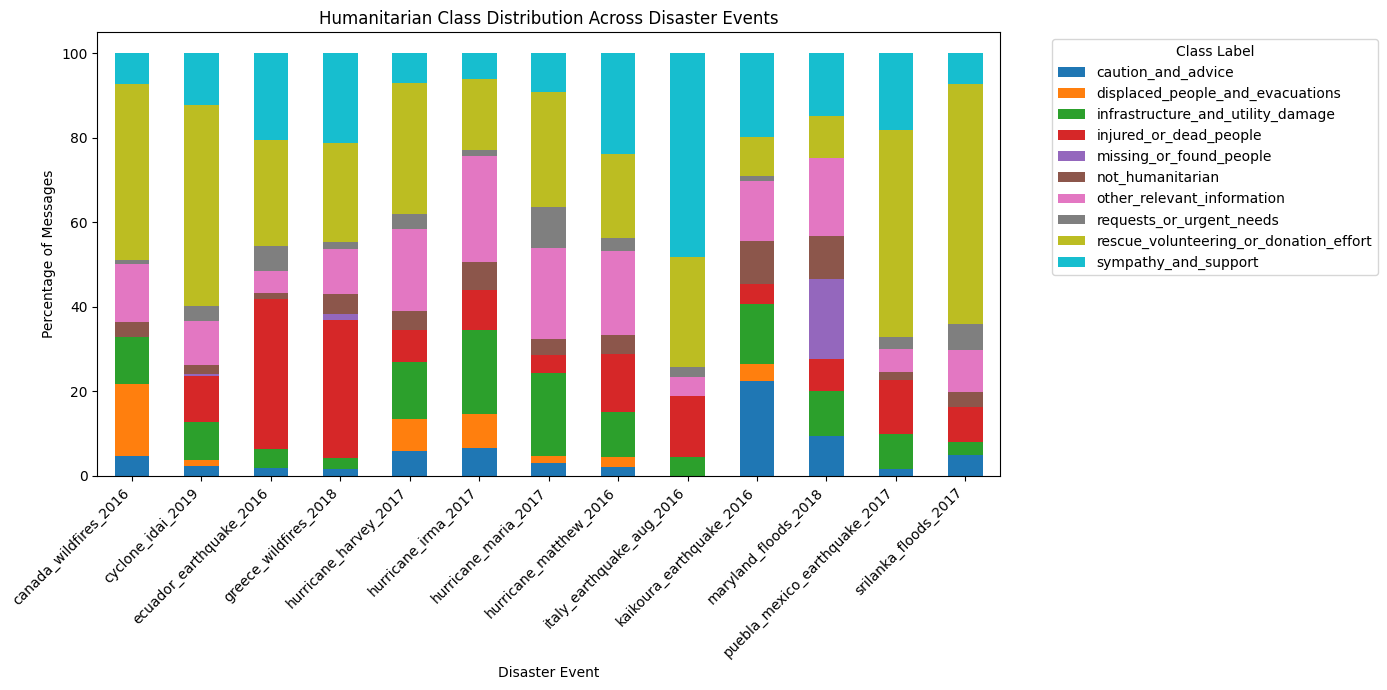

In [21]:
# Visualize class distributions across disaster events

event_class_percentages.plot(
    kind="bar",
    stacked=True,
    figsize=(14, 7)
)

plt.title("Humanitarian Class Distribution Across Disaster Events")
plt.xlabel("Disaster Event")
plt.ylabel("Percentage of Messages")
plt.legend(
    title="Class Label",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.show()

## **Observations**

- The combined dataset contains 43,409 messages from 13 disaster events.
- No missing values or duplicate tweet IDs were identified.
- The humanitarian classes are substantially imbalanced. The largest class,
  `rescue_volunteering_or_donation_effort`, represents approximately 28% of
  all messages, whereas `missing_or_found_people` represents less than 1%.
- Class distributions vary considerably across disaster events, indicating
  that different disasters contain different mixtures of humanitarian
  information.
- Some classes are absent from several disaster events. In particular,
  `missing_or_found_people` is strongly concentrated in the Maryland floods
  dataset.
- Because event-specific class distributions differ substantially, evaluation
  using only mixed-event train/test data may not fully represent performance
  on a previously unseen disaster.

Based on these observations, model performance will be evaluated using the
provided train, development, and test splits, with an additional event-level
generalization experiment considered to assess performance on an unseen
disaster.

## **5. Data Preparation for Modelling**

The original HumAID train, development, and test assignments will be preserved
for the initial modelling experiment.

The training set will be used to fit the text representation and classifier.
The development set will be used during model development and comparison,
while the test set will remain unseen until final evaluation

In [22]:
# Separate the combined dataset using the original HumAID splits

train_df = full_df[full_df["original_split"] == "train"].copy()
dev_df = full_df[full_df["original_split"] == "dev"].copy()
test_df = full_df[full_df["original_split"] == "test"].copy()

print("Training set:", train_df.shape)
print("Development set:", dev_df.shape)
print("Test set:", test_df.shape)

print("\nTotal rows:",
      len(train_df) + len(dev_df) + len(test_df))

Training set: (30381, 5)
Development set: (4422, 5)
Test set: (8606, 5)

Total rows: 43409


In [23]:
# Define text features and target labels

X_train = train_df["tweet_text"]
y_train = train_df["class_label"]

X_dev = dev_df["tweet_text"]
y_dev = dev_df["class_label"]

X_test = test_df["tweet_text"]
y_test = test_df["class_label"]

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("\nExample input message:")
print(X_train.iloc[0])

print("\nCorresponding target label:")
print(y_train.iloc[0])

X_train shape: (30381,)
y_train shape: (30381,)

Example input message:
RT @DonBradshawNTV: How @MarshallAmpsUK came to the assistance of Fort McMurray wildfire victim, tonite on @NTVNewsNL at 6 pm.

Corresponding target label:
other_relevant_information


## **6. Text Feature Engineering**

Machine-learning classifiers require numerical input rather than raw text.
The crisis messages will therefore be transformed into numerical features
using Term Frequency–Inverse Document Frequency (TF-IDF).

TF-IDF represents each message according to the words it contains while
reducing the influence of words that occur very frequently across the
collection of messages.

To prevent data leakage, the TF-IDF vectorizer will be fitted using only the
training data. The fitted vectorizer will then be used to transform the
development and test sets.

In [24]:
# Initialize the TF-IDF vectorizer

tfidf = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    max_features=10000
)

tfidf

TfidfVectorizer(max_features=10000, stop_words='english')

In [25]:
# Fit TF-IDF on the training text and transform the training data

X_train_tfidf = tfidf.fit_transform(X_train)

print("Original X_train shape:", X_train.shape)
print("TF-IDF X_train shape:", X_train_tfidf.shape)

Original X_train shape: (30381,)
TF-IDF X_train shape: (30381, 10000)


In [26]:
# Transform the development and test text using the fitted vectorizer

X_dev_tfidf = tfidf.transform(X_dev)
X_test_tfidf = tfidf.transform(X_test)

print("Training matrix:", X_train_tfidf.shape)
print("Development matrix:", X_dev_tfidf.shape)
print("Test matrix:", X_test_tfidf.shape)

Training matrix: (30381, 10000)
Development matrix: (4422, 10000)
Test matrix: (8606, 10000)


In [27]:
# Inspect the learned TF-IDF vocabulary

feature_names = tfidf.get_feature_names_out()

print("Number of TF-IDF features:", len(feature_names))
print("\nFirst 30 features:")
print(feature_names[:30])

Number of TF-IDF features: 10000

First 30 features:
['00' '000' '000s' '000usd' '002' '0051' '00am' '00pm' '01' '0172' '02'
 '03' '0303pst' '04' '05' '06' '07' '08' '0800' '09' '10' '100' '1000'
 '100000' '1000s' '100k' '100m' '100s' '101' '101cab']


In [28]:
# Inspect the TF-IDF matrix type and sparsity

print("Matrix type:")
print(type(X_train_tfidf))

print("\nMatrix shape:")
print(X_train_tfidf.shape)

print("\nNumber of stored non-zero values:")
print(X_train_tfidf.nnz)

total_values = X_train_tfidf.shape[0] * X_train_tfidf.shape[1]
sparsity = 1 - (X_train_tfidf.nnz / total_values)

print(f"\nMatrix sparsity: {sparsity:.2%}")

Matrix type:
<class 'scipy.sparse._csr.csr_matrix'>

Matrix shape:
(30381, 10000)

Number of stored non-zero values:
310311

Matrix sparsity: 99.90%


## **7. Baseline Modelling**

Before training the main classifier, a simple baseline will be established.

A baseline provides a reference point for determining whether the machine-
learning model is learning useful patterns beyond a trivial prediction
strategy.

Because the target classes are imbalanced, model performance will be evaluated
using both overall accuracy and macro-averaged F1-score. Class-level precision,
recall, and F1-score will also be examined.

In [29]:
# Import additional evaluation metric

from sklearn.metrics import f1_score

In [30]:
# Identify the majority class in the training data

majority_class = y_train.value_counts().idxmax()
majority_count = y_train.value_counts().max()
majority_percentage = majority_count / len(y_train) * 100

print("Majority class:", majority_class)
print("Training examples in majority class:", majority_count)
print(f"Percentage of training data: {majority_percentage:.2f}%")

Majority class: rescue_volunteering_or_donation_effort
Training examples in majority class: 8512
Percentage of training data: 28.02%


In [31]:
# Create majority-class baseline predictions for the development set

baseline_predictions = np.full(
    len(y_dev),
    majority_class
)

baseline_accuracy = accuracy_score(y_dev, baseline_predictions)
baseline_macro_f1 = f1_score(
    y_dev,
    baseline_predictions,
    average="macro"
)

print(f"Baseline accuracy: {baseline_accuracy:.3f}")
print(f"Baseline macro-F1: {baseline_macro_f1:.3f}")

Baseline accuracy: 0.280
Baseline macro-F1: 0.044


### **Logistic Regression Baseline Classifier**

A Logistic Regression classifier will be trained using the TF-IDF features.

Logistic Regression provides a computationally efficient and interpretable
baseline for high-dimensional sparse text data. Its performance will first be
evaluated on the development set before any final evaluation is performed on
the held-out test set.

In [32]:
# Initialize the Logistic Regression classifier

logreg = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logreg

LogisticRegression(max_iter=1000, random_state=42)

In [33]:
# Train the classifier on the TF-IDF training features

logreg.fit(X_train_tfidf, y_train)

LogisticRegression(max_iter=1000, random_state=42)

In [34]:
# Generate predictions for the development set

y_dev_pred = logreg.predict(X_dev_tfidf)

print("Number of predictions:", len(y_dev_pred))

print("\nFirst 10 predicted labels:")
print(y_dev_pred[:10])

print("\nFirst 10 actual labels:")
print(y_dev.iloc[:10].values)

Number of predictions: 4422

First 10 predicted labels:
['rescue_volunteering_or_donation_effort' 'sympathy_and_support'
 'rescue_volunteering_or_donation_effort'
 'infrastructure_and_utility_damage' 'other_relevant_information'
 'rescue_volunteering_or_donation_effort'
 'rescue_volunteering_or_donation_effort' 'other_relevant_information'
 'other_relevant_information' 'displaced_people_and_evacuations']

First 10 actual labels:
['rescue_volunteering_or_donation_effort' 'sympathy_and_support'
 'rescue_volunteering_or_donation_effort'
 'infrastructure_and_utility_damage' 'other_relevant_information'
 'rescue_volunteering_or_donation_effort'
 'rescue_volunteering_or_donation_effort'
 'infrastructure_and_utility_damage'
 'rescue_volunteering_or_donation_effort'
 'displaced_people_and_evacuations']


In [35]:
# Evaluate overall development-set performance

dev_accuracy = accuracy_score(y_dev, y_dev_pred)

dev_macro_f1 = f1_score(
    y_dev,
    y_dev_pred,
    average="macro"
)

print(f"Development accuracy: {dev_accuracy:.3f}")
print(f"Development macro-F1: {dev_macro_f1:.3f}")

Development accuracy: 0.754
Development macro-F1: 0.696


In [36]:
# Display class-level performance on the development set

print(
    classification_report(
        y_dev,
        y_dev_pred,
        zero_division=0
    )
)

                                        precision    recall  f1-score   support

                    caution_and_advice       0.77      0.53      0.63       233
      displaced_people_and_evacuations       0.92      0.86      0.89       218
     infrastructure_and_utility_damage       0.80      0.83      0.82       615
                injured_or_dead_people       0.91      0.90      0.90       433
               missing_or_found_people       0.86      0.67      0.75        18
                      not_humanitarian       0.48      0.13      0.20       204
            other_relevant_information       0.55      0.67      0.60       778
              requests_or_urgent_needs       0.65      0.45      0.53       166
rescue_volunteering_or_donation_effort       0.79      0.88      0.83      1239
                  sympathy_and_support       0.86      0.76      0.81       518

                              accuracy                           0.75      4422
                             macro avg

### **Development Set Confusion Matrix**

Although aggregate metrics summarize overall classifier performance, they do
not show which humanitarian categories are being confused with one another.

A confusion matrix will therefore be used to examine the pattern of
misclassifications across the development set. Both raw counts and normalized
values will be considered, since the target classes are imbalanced.

In [37]:
# Define a consistent class order for evaluation

class_names = sorted(y_train.unique())

print("Number of classes:", len(class_names))

for class_name in class_names:
    print(class_name)

Number of classes: 10
caution_and_advice
displaced_people_and_evacuations
infrastructure_and_utility_damage
injured_or_dead_people
missing_or_found_people
not_humanitarian
other_relevant_information
requests_or_urgent_needs
rescue_volunteering_or_donation_effort
sympathy_and_support


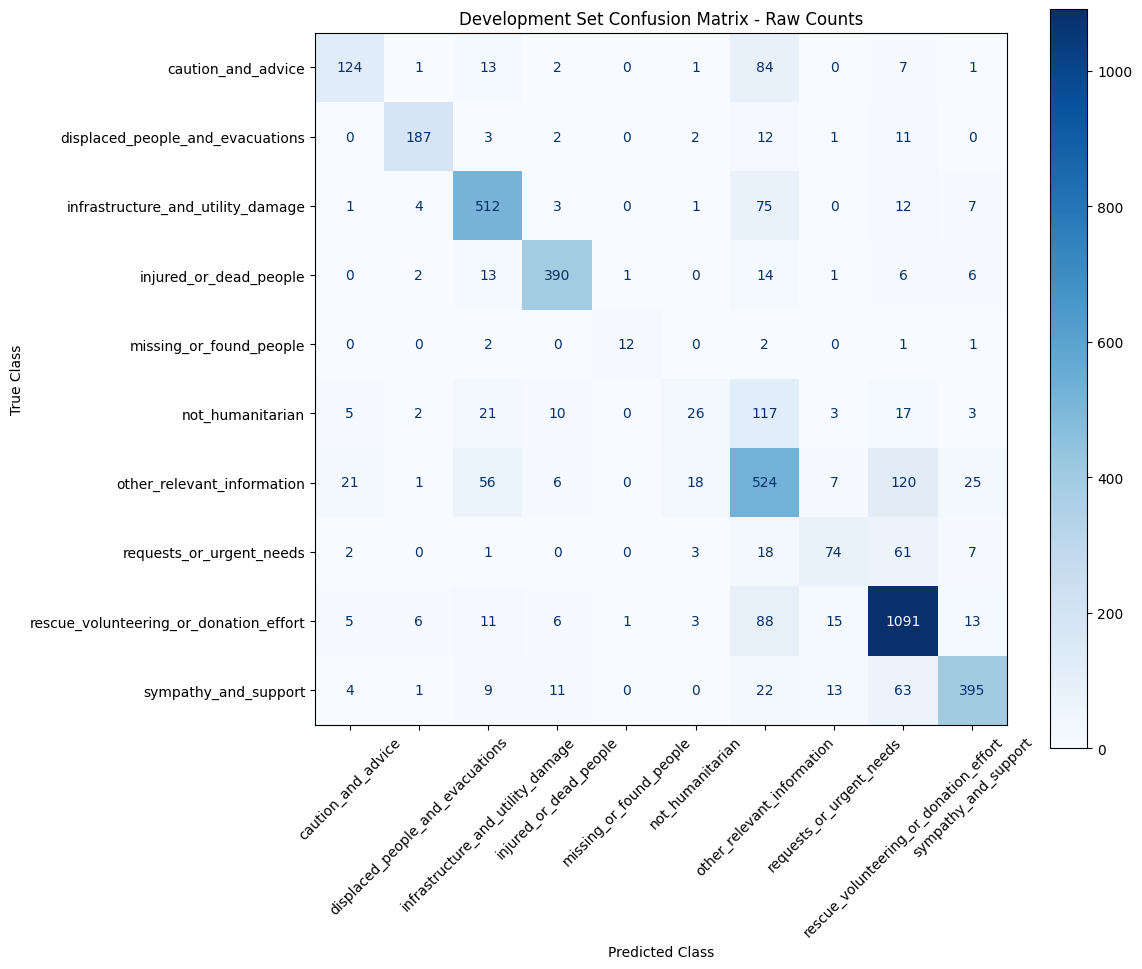

In [38]:
# Plot the confusion matrix using raw prediction counts

fig, ax = plt.subplots(figsize=(12, 10))

ConfusionMatrixDisplay.from_predictions(
    y_dev,
    y_dev_pred,
    labels=class_names,
    xticks_rotation=45,
    cmap="Blues",
    ax=ax
)

plt.title("Development Set Confusion Matrix - Raw Counts")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.tight_layout()

plt.show()

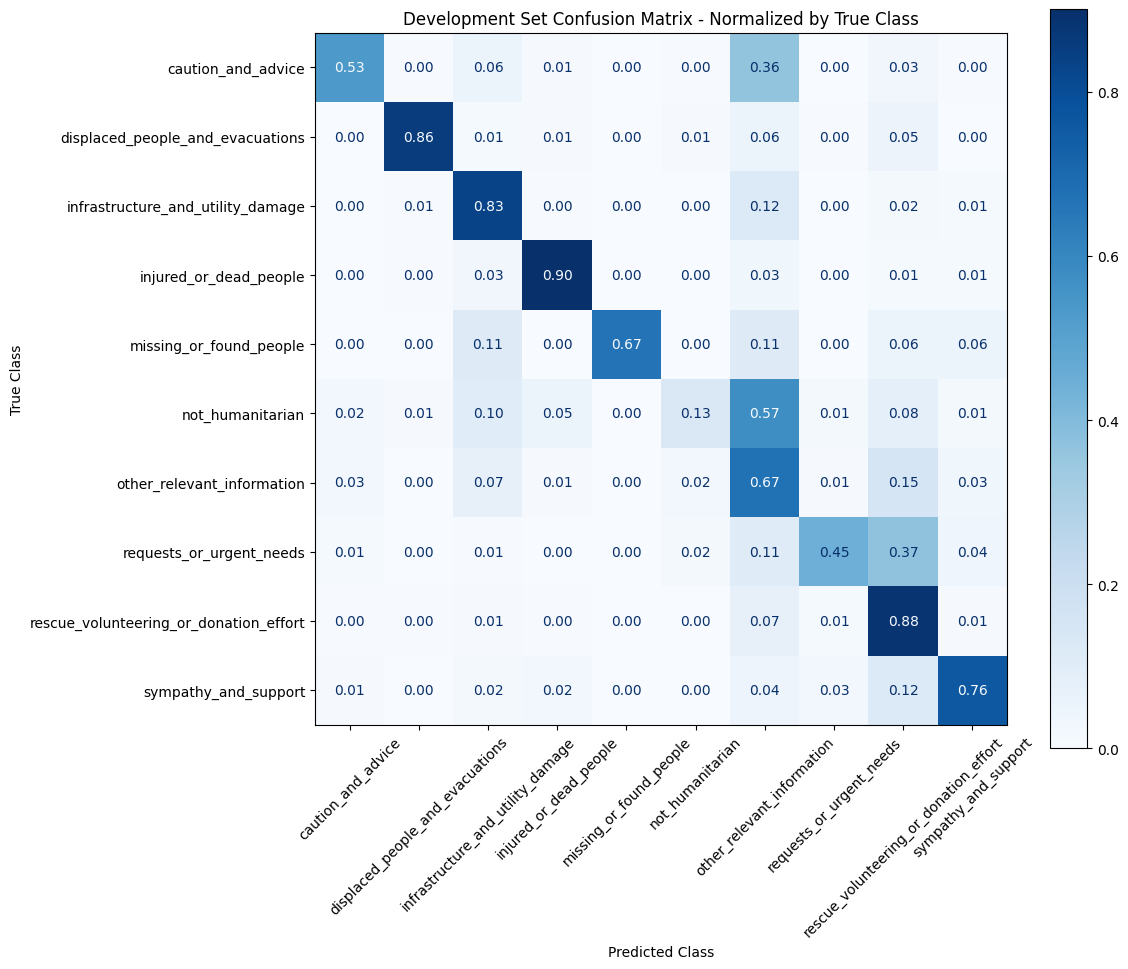

In [39]:
# Plot the confusion matrix normalized by true class

fig, ax = plt.subplots(figsize=(12, 10))

ConfusionMatrixDisplay.from_predictions(
    y_dev,
    y_dev_pred,
    labels=class_names,
    normalize="true",
    values_format=".2f",
    xticks_rotation=45,
    cmap="Blues",
    ax=ax
)

plt.title("Development Set Confusion Matrix - Normalized by True Class")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.tight_layout()

plt.show()

In [40]:
# Identify the most frequent class-to-class confusions

cm = confusion_matrix(
    y_dev,
    y_dev_pred,
    labels=class_names
)

confusion_records = []

for true_index, true_class in enumerate(class_names):
    for pred_index, predicted_class in enumerate(class_names):

        # Ignore correct predictions on the diagonal
        if true_class != predicted_class:

            confusion_records.append({
                "true_class": true_class,
                "predicted_class": predicted_class,
                "count": cm[true_index, pred_index]
            })

confusion_df = pd.DataFrame(confusion_records)

confusion_df = confusion_df.sort_values(
    "count",
    ascending=False
)

confusion_df.head(15)

,true_class,predicted_class,count
61,other_relevant_information,rescue_volunteering_or_donation_effort,120
50,not_humanitarian,other_relevant_information,117
78,rescue_volunteering_or_donation_effort,other_relevant_information,88
5,caution_and_advice,other_relevant_information,84
23,infrastructure_and_utility_damage,other_relevant_information,75
89,sympathy_and_support,rescue_volunteering_or_donation_effort,63
70,requests_or_urgent_needs,rescue_volunteering_or_donation_effort,61
56,other_relevant_information,infrastructure_and_utility_damage,56
62,other_relevant_information,sympathy_and_support,25
87,sympathy_and_support,other_relevant_information,22


## **Baseline Model Observations**

The TF-IDF + Logistic Regression baseline achieved a development accuracy of
75.4% and a macro-F1 score of 69.6%.

Performance varied considerably across humanitarian categories. The model
performed particularly well for `injured_or_dead_people`,
`displaced_people_and_evacuations`, `rescue_volunteering_or_donation_effort`,
and `infrastructure_and_utility_damage`.

The confusion matrix identified several important error patterns:

- `other_relevant_information` acts as a frequent destination for
  misclassified messages. For example, 57% of `not_humanitarian` messages
  and 36% of `caution_and_advice` messages were classified as
  `other_relevant_information`.
- `requests_or_urgent_needs` was frequently confused with
  `rescue_volunteering_or_donation_effort`, with 37% of true urgent-needs
  messages assigned to the rescue/donation category.
- Performance for `missing_or_found_people` appears relatively strong, but
  the development set contains only 18 examples of this class. This result
  should therefore be interpreted cautiously.
- The difference between overall accuracy and macro-F1 indicates that
  performance is not uniform across classes.

These results suggest that the baseline captures useful humanitarian
information patterns, but class imbalance and semantic overlap between
categories remain important sources of error.


## **8. Model Improvement**

The baseline model showed uneven performance across humanitarian categories,
particularly for less well-recognized classes.

As a first improvement, class weighting will be evaluated. Class weighting
increases the influence of underrepresented classes during model training
without altering the original training data.

The weighted model will be evaluated on the development set and compared with
the unweighted baseline using accuracy and macro-F1.

In [41]:
# Train Logistic Regression with balanced class weights

logreg_balanced = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

logreg_balanced.fit(X_train_tfidf, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

In [42]:
# Evaluate the class-weighted model on the development set

y_dev_pred_balanced = logreg_balanced.predict(X_dev_tfidf)

balanced_accuracy = accuracy_score(
    y_dev,
    y_dev_pred_balanced
)

balanced_macro_f1 = f1_score(
    y_dev,
    y_dev_pred_balanced,
    average="macro"
)

print(f"Baseline accuracy:      {dev_accuracy:.3f}")
print(f"Balanced accuracy:      {balanced_accuracy:.3f}")

print(f"\nBaseline macro-F1:      {dev_macro_f1:.3f}")
print(f"Balanced macro-F1:      {balanced_macro_f1:.3f}")

Baseline accuracy:      0.754
Balanced accuracy:      0.722

Baseline macro-F1:      0.696
Balanced macro-F1:      0.699


In [43]:
# Display class-level performance for the class-weighted model

print(
    classification_report(
        y_dev,
        y_dev_pred_balanced,
        zero_division=0
    )
)

                                        precision    recall  f1-score   support

                    caution_and_advice       0.54      0.71      0.62       233
      displaced_people_and_evacuations       0.84      0.91      0.87       218
     infrastructure_and_utility_damage       0.81      0.82      0.81       615
                injured_or_dead_people       0.90      0.91      0.90       433
               missing_or_found_people       0.67      0.89      0.76        18
                      not_humanitarian       0.30      0.43      0.35       204
            other_relevant_information       0.56      0.49      0.52       778
              requests_or_urgent_needs       0.43      0.73      0.54       166
rescue_volunteering_or_donation_effort       0.88      0.75      0.81      1239
                  sympathy_and_support       0.84      0.78      0.81       518

                              accuracy                           0.72      4422
                             macro avg

In [44]:
# Compare baseline and class-weighted model performance

model_comparison = pd.DataFrame({
    "model": [
        "Logistic Regression",
        "Logistic Regression - Balanced"
    ],
    "accuracy": [
        dev_accuracy,
        balanced_accuracy
    ],
    "macro_f1": [
        dev_macro_f1,
        balanced_macro_f1
    ]
})

model_comparison

,model,accuracy,macro_f1
0,Logistic Regression,0.754184,0.695743
1,Logistic Regression - Balanced,0.722298,0.698960


### **Class Weighting Observation**

Applying balanced class weights produced only a negligible improvement in
macro-F1 (0.696 to 0.699), while overall development accuracy decreased from
75.4% to 72.2%.

This suggests that class weighting alone does not meaningfully improve the
current model. The unweighted Logistic Regression model will therefore remain
the stronger baseline for subsequent comparison.

### **Linear Support Vector Machine**

A Linear Support Vector Machine (Linear SVM) will be evaluated as an
alternative classifier.

Linear SVMs are well suited to high-dimensional sparse feature spaces such as
TF-IDF text representations. The model will be trained using the same training
features and evaluated on the same development set to allow direct comparison
with Logistic Regression.

In [45]:
# Import Linear Support Vector Machine classifier

from sklearn.svm import LinearSVC

In [46]:
# Train a Linear SVM classifier

linear_svm = LinearSVC(
    random_state=42
)

linear_svm.fit(X_train_tfidf, y_train)

LinearSVC(random_state=42)

In [47]:
# Generate development-set predictions using Linear SVM

y_dev_pred_svm = linear_svm.predict(X_dev_tfidf)

svm_accuracy = accuracy_score(
    y_dev,
    y_dev_pred_svm
)

svm_macro_f1 = f1_score(
    y_dev,
    y_dev_pred_svm,
    average="macro"
)

print(f"Linear SVM accuracy: {svm_accuracy:.3f}")
print(f"Linear SVM macro-F1: {svm_macro_f1:.3f}")

Linear SVM accuracy: 0.741
Linear SVM macro-F1: 0.697


In [48]:
# Compare development-set performance across models

model_comparison = pd.DataFrame({
    "model": [
        "Logistic Regression",
        "Logistic Regression - Balanced",
        "Linear SVM"
    ],
    "accuracy": [
        dev_accuracy,
        balanced_accuracy,
        svm_accuracy
    ],
    "macro_f1": [
        dev_macro_f1,
        balanced_macro_f1,
        svm_macro_f1
    ]
})

model_comparison.sort_values(
    "macro_f1",
    ascending=False
).reset_index(drop=True)

,model,accuracy,macro_f1
0,Logistic Regression - Balanced,0.722298,0.698960
1,Linear SVM,0.740615,0.696923
2,Logistic Regression,0.754184,0.695743


In [49]:
# Display class-level performance for Linear SVM

print(
    classification_report(
        y_dev,
        y_dev_pred_svm,
        zero_division=0
    )
)

                                        precision    recall  f1-score   support

                    caution_and_advice       0.65      0.58      0.61       233
      displaced_people_and_evacuations       0.88      0.90      0.89       218
     infrastructure_and_utility_damage       0.78      0.85      0.81       615
                injured_or_dead_people       0.90      0.92      0.91       433
               missing_or_found_people       0.88      0.78      0.82        18
                      not_humanitarian       0.37      0.18      0.24       204
            other_relevant_information       0.55      0.57      0.56       778
              requests_or_urgent_needs       0.58      0.45      0.51       166
rescue_volunteering_or_donation_effort       0.79      0.85      0.82      1239
                  sympathy_and_support       0.82      0.77      0.80       518

                              accuracy                           0.74      4422
                             macro avg

### **Model Comparison and Selection**

Three classifier configurations were compared using the development set:

- Logistic Regression
- Logistic Regression with balanced class weights
- Linear Support Vector Machine (Linear SVM)

The models produced similar macro-F1 scores of approximately 0.70. Balanced
Logistic Regression produced the highest macro-F1 (0.699), but this represented
only a negligible improvement over standard Logistic Regression (0.696) while
reducing accuracy from 75.4% to 72.2%.

Linear SVM achieved a macro-F1 of 0.697 and an accuracy of 74.1%. Although it
improved performance for some individual classes, these gains were accompanied
by reduced performance in others.

Standard Logistic Regression was therefore retained as the primary model. It
provided the highest overall development accuracy with comparable macro-F1
performance, while also providing class-probability estimates that can later
be incorporated into the interactive prototype.

## **9. Final Model Evaluation**

Following model comparison on the development set, standard Logistic Regression
was selected as the primary classifier.

The selected model will now be evaluated on the held-out test set. The test
data were not used for model fitting or model selection, providing an
independent assessment of classification performance on unseen messages from
the represented disaster events.

In [50]:
# Generate predictions for the held-out test set

y_test_pred = logreg.predict(X_test_tfidf)

test_accuracy = accuracy_score(
    y_test,
    y_test_pred
)

test_macro_f1 = f1_score(
    y_test,
    y_test_pred,
    average="macro"
)

print(f"Test accuracy: {test_accuracy:.3f}")
print(f"Test macro-F1: {test_macro_f1:.3f}")

Test accuracy: 0.748
Test macro-F1: 0.679


In [51]:
# Display class-level performance on the held-out test set

print(
    classification_report(
        y_test,
        y_test_pred,
        zero_division=0
    )
)

                                        precision    recall  f1-score   support

                    caution_and_advice       0.72      0.50      0.59       454
      displaced_people_and_evacuations       0.90      0.82      0.86       422
     infrastructure_and_utility_damage       0.83      0.87      0.85      1197
                injured_or_dead_people       0.90      0.92      0.91       840
               missing_or_found_people       0.81      0.61      0.70        36
                      not_humanitarian       0.41      0.12      0.18       392
            other_relevant_information       0.54      0.66      0.60      1516
              requests_or_urgent_needs       0.60      0.41      0.49       328
rescue_volunteering_or_donation_effort       0.77      0.87      0.82      2413
                  sympathy_and_support       0.87      0.74      0.80      1008

                              accuracy                           0.75      8606
                             macro avg

In [52]:
# Compare development and test performance

final_performance = pd.DataFrame({
    "dataset": [
        "Development",
        "Test"
    ],
    "accuracy": [
        dev_accuracy,
        test_accuracy
    ],
    "macro_f1": [
        dev_macro_f1,
        test_macro_f1
    ]
})

final_performance

,dataset,accuracy,macro_f1
0,Development,0.754184,0.695743
1,Test,0.747850,0.679024


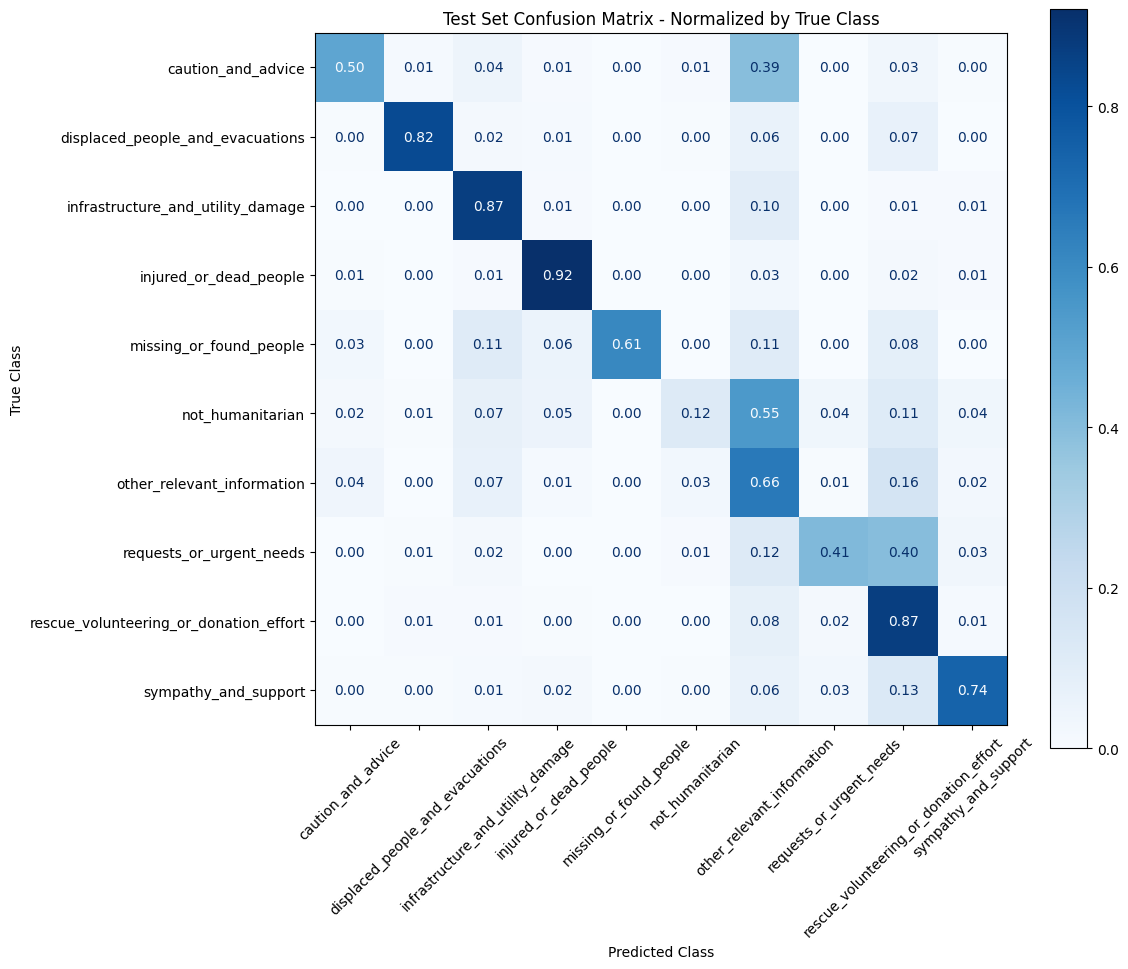

In [53]:
# Plot the normalized confusion matrix for the held-out test set

fig, ax = plt.subplots(figsize=(12, 10))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    labels=class_names,
    normalize="true",
    values_format=".2f",
    xticks_rotation=45,
    cmap="Blues",
    ax=ax
)

plt.title("Test Set Confusion Matrix - Normalized by True Class")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.tight_layout()

plt.show()

## **10. Generalization to an Unseen Disaster Event**

The standard test set contains unseen messages, but those messages originate
from disaster events that are also represented in the training data.

A real-world deployment may instead encounter messages from a newly occurring
disaster. An additional event-level experiment will therefore be performed to
investigate how well the model generalizes when an entire disaster event is
excluded from training.

Because humanitarian class distributions vary substantially between events,
the selection and interpretation of the held-out event require particular
care.

### **Leave-One-Event-Out Evaluation**

To simulate deployment during a previously unseen disaster, a leave-one-event-out
evaluation will be performed.

For each iteration, one complete disaster event will be held out as the
evaluation set, while the remaining events will be used for training. A new
TF-IDF vectorizer and Logistic Regression classifier will be fitted during each
iteration to prevent information from the held-out event from influencing
feature construction or model training.

Performance will be measured separately for each held-out disaster using
accuracy and macro-F1.

In [54]:
# Show all pandas DataFrames currently stored in memory

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        print(name, obj.shape)

_ (2, 3)
__ (3, 3)
sample_df (228, 3)
_9 (5, 3)
df (392, 5)
inventory_df (39, 6)
_10 (39, 6)
event_split_counts (13, 4)
_12 (13, 4)
class_distribution_df (10, 3)
_15 (10, 3)
full_df (43409, 5)
_17 (5, 5)
event_class_counts (13, 10)
_19 (13, 10)
event_class_percentages (13, 10)
_20 (13, 10)
train_df (30381, 5)
dev_df (4422, 5)
test_df (8606, 5)
confusion_df (90, 3)
_40 (15, 3)
model_comparison (3, 3)
_44 (2, 3)
_48 (3, 3)
final_performance (2, 3)
_52 (2, 3)


In [55]:
# Create a list for storing leave-one-event-out results

event_results = []

events = sorted(full_df["event"].unique())

print("Number of events:", len(events))

for event in events:
    print(event)

Number of events: 13
canada_wildfires_2016
cyclone_idai_2019
ecuador_earthquake_2016
greece_wildfires_2018
hurricane_harvey_2017
hurricane_irma_2017
hurricane_maria_2017
hurricane_matthew_2016
italy_earthquake_aug_2016
kaikoura_earthquake_2016
maryland_floods_2018
puebla_mexico_earthquake_2017
srilanka_floods_2017


In [57]:
# Perform leave-one-event-out evaluation

event_results = []

for held_out_event in events:

    # Separate the held-out disaster from all remaining disasters
    event_train_df = full_df[
        full_df["event"] != held_out_event
    ].copy()

    event_test_df = full_df[
        full_df["event"] == held_out_event
    ].copy()


    # Define input text and target labels
    X_event_train = event_train_df["tweet_text"]
    y_event_train = event_train_df["class_label"]

    X_event_test = event_test_df["tweet_text"]
    y_event_test = event_test_df["class_label"]

    # Create a NEW TF-IDF vectorizer for this iteration
    event_tfidf = TfidfVectorizer(
        lowercase=True,
        stop_words="english",
        max_features=10000
    )

    # Learn the vocabulary only from the training events
    X_event_train_tfidf = event_tfidf.fit_transform(
        X_event_train
    )

    # Transform the unseen event using the learned vocabulary
    X_event_test_tfidf = event_tfidf.transform(
        X_event_test
    )

    # Train a NEW Logistic Regression model
    event_model = LogisticRegression(
        max_iter=1000,
        random_state=42
    )

    event_model.fit(
        X_event_train_tfidf,
        y_event_train
    )

    # Predict labels for the unseen disaster
    y_event_pred = event_model.predict(
        X_event_test_tfidf
    )

    # Calculate evaluation metrics
    event_accuracy = accuracy_score(
        y_event_test,
        y_event_pred
    )

    event_macro_f1 = f1_score(
        y_event_test,
        y_event_pred,
        average="macro",
        zero_division=0
    )

    # Store results from this iteration
    event_results.append({
        "held_out_event": held_out_event,
        "n_train": len(event_train_df),
        "n_test": len(event_test_df),
        "n_test_classes": y_event_test.nunique(),
        "accuracy": event_accuracy,
        "macro_f1": event_macro_f1
    })

    print(
        f"Completed: {held_out_event} "
        f"| Accuracy: {event_accuracy:.3f} "
        f"| Macro-F1: {event_macro_f1:.3f}"
    )

Completed: canada_wildfires_2016 | Accuracy: 0.780 | Macro-F1: 0.543
Completed: cyclone_idai_2019 | Accuracy: 0.743 | Macro-F1: 0.506
Completed: ecuador_earthquake_2016 | Accuracy: 0.831 | Macro-F1: 0.655
Completed: greece_wildfires_2018 | Accuracy: 0.690 | Macro-F1: 0.482
Completed: hurricane_harvey_2017 | Accuracy: 0.723 | Macro-F1: 0.581
Completed: hurricane_irma_2017 | Accuracy: 0.700 | Macro-F1: 0.629
Completed: hurricane_maria_2017 | Accuracy: 0.695 | Macro-F1: 0.658
Completed: hurricane_matthew_2016 | Accuracy: 0.742 | Macro-F1: 0.651
Completed: italy_earthquake_aug_2016 | Accuracy: 0.786 | Macro-F1: 0.455
Completed: kaikoura_earthquake_2016 | Accuracy: 0.638 | Macro-F1: 0.629
Completed: maryland_floods_2018 | Accuracy: 0.492 | Macro-F1: 0.373
Completed: puebla_mexico_earthquake_2017 | Accuracy: 0.784 | Macro-F1: 0.553
Completed: srilanka_floods_2017 | Accuracy: 0.670 | Macro-F1: 0.464


In [58]:
# Convert event-level results into a DataFrame

event_results_df = pd.DataFrame(event_results)

event_results_df = event_results_df.sort_values(
    "macro_f1",
    ascending=False
).reset_index(drop=True)

event_results_df

,held_out_event,n_train,n_test,n_test_classes,accuracy,macro_f1
0,hurricane_maria_2017,36131,7278,9,0.695246,0.657930
1,ecuador_earthquake_2016,41846,1563,8,0.831094,0.655043
2,hurricane_matthew_2016,41755,1654,9,0.742443,0.650619
3,hurricane_irma_2017,34010,9399,9,0.700074,0.629166
4,kaikoura_earthquake_2016,41214,2195,9,0.637813,0.628738
5,hurricane_harvey_2017,34297,9112,9,0.723003,0.580931
6,puebla_mexico_earthquake_2017,41394,2015,8,0.783623,0.553299
7,canada_wildfires_2016,41167,2242,8,0.780107,0.543143
8,cyclone_idai_2019,39476,3933,10,0.742690,0.506388
9,greece_wildfires_2018,41894,1515,9,0.690429,0.482287


In [59]:
# Summarize performance across unseen disaster events

print("Leave-One-Event-Out Performance")
print("--------------------------------")

print(
    f"Mean accuracy: "
    f"{event_results_df['accuracy'].mean():.3f}"
)

print(
    f"Accuracy range: "
    f"{event_results_df['accuracy'].min():.3f} - "
    f"{event_results_df['accuracy'].max():.3f}"
)

print(
    f"\nMean macro-F1: "
    f"{event_results_df['macro_f1'].mean():.3f}"
)

print(
    f"Macro-F1 range: "
    f"{event_results_df['macro_f1'].min():.3f} - "
    f"{event_results_df['macro_f1'].max():.3f}"
)

Leave-One-Event-Out Performance
--------------------------------
Mean accuracy: 0.713
Accuracy range: 0.492 - 0.831

Mean macro-F1: 0.552
Macro-F1 range: 0.373 - 0.658


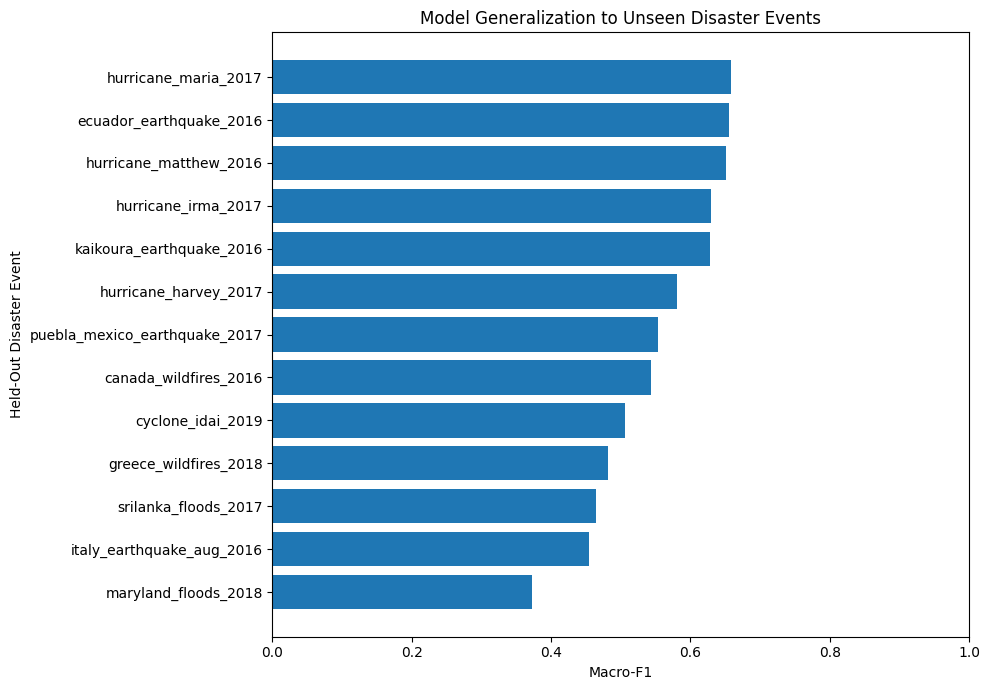

In [60]:
# Visualize performance for each held-out disaster

plot_df = event_results_df.sort_values(
    "macro_f1",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    plot_df["held_out_event"],
    plot_df["macro_f1"]
)

plt.xlabel("Macro-F1")
plt.ylabel("Held-Out Disaster Event")
plt.title(
    "Model Generalization to Unseen Disaster Events"
)

plt.xlim(0, 1)
plt.tight_layout()
plt.show()

In [61]:
# Compare event size, class coverage, and model performance

event_diagnostics = event_results_df[
    [
        "held_out_event",
        "n_test",
        "n_test_classes",
        "accuracy",
        "macro_f1"
    ]
].copy()

event_diagnostics

,held_out_event,n_test,n_test_classes,accuracy,macro_f1
0,hurricane_maria_2017,7278,9,0.695246,0.657930
1,ecuador_earthquake_2016,1563,8,0.831094,0.655043
2,hurricane_matthew_2016,1654,9,0.742443,0.650619
3,hurricane_irma_2017,9399,9,0.700074,0.629166
4,kaikoura_earthquake_2016,2195,9,0.637813,0.628738
5,hurricane_harvey_2017,9112,9,0.723003,0.580931
6,puebla_mexico_earthquake_2017,2015,8,0.783623,0.553299
7,canada_wildfires_2016,2242,8,0.780107,0.543143
8,cyclone_idai_2019,3933,10,0.742690,0.506388
9,greece_wildfires_2018,1515,9,0.690429,0.482287


### **Unseen-Event Generalization Observations**

Leave-one-event-out evaluation produced a mean accuracy of 71.3% and a mean
macro-F1 of 55.2%. Performance varied substantially between disaster events,
with accuracy ranging from 49.2% to 83.1% and macro-F1 ranging from 37.3% to
65.8%.

These results are weaker and considerably more variable than performance on
the standard test set, where the selected Logistic Regression model achieved
74.8% accuracy and a macro-F1 of 67.9%. This indicates that performance on
unseen messages from previously represented disaster events does not fully
reflect performance on an entirely new disaster.

The Maryland floods produced the lowest unseen-event performance, with 49.2%
accuracy and a macro-F1 of 37.3%. Earlier exploratory analysis showed that the
rare `missing_or_found_people` category is strongly concentrated in this
event. Holding Maryland out therefore creates both an event-level domain shift
and a substantial shift in the representation of this class.

Accuracy and macro-F1 also provide different perspectives across events. For
example, the Italy earthquake achieved 78.6% accuracy but only 45.5%
macro-F1. This reflects the importance of considering class imbalance and
per-class performance rather than relying on accuracy alone.

Overall, the experiment suggests that the classifier learns useful
humanitarian language patterns that transfer between disasters, but its
performance is sensitive to event-specific vocabulary and class
distributions. In a real deployment, predictions for a newly emerging
disaster should therefore be interpreted cautiously, particularly for rare
or poorly represented humanitarian categories.

## **11. Building the Final Inference Pipeline**

The selected TF-IDF and Logistic Regression components will now be combined
into a single scikit-learn Pipeline.

Packaging preprocessing and classification together ensures that the same
text transformation learned during training is automatically applied during
inference. This also simplifies deployment because the application can receive
raw message text directly rather than separately managing the vectorizer and
classifier.

In [62]:
from sklearn.pipeline import Pipeline

In [63]:
# Build the final inference pipeline

final_pipeline = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            lowercase=True,
            stop_words="english",
            max_features=10000
        )
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            random_state=42
        )
    )
])

final_pipeline

Pipeline(steps=[('tfidf',
                 TfidfVectorizer(max_features=10000, stop_words='english')),
                ('classifier',
                 LogisticRegression(max_iter=1000, random_state=42))])

In [64]:
# Combine training and development data for the deployable model

deployment_train_df = pd.concat(
    [train_df, dev_df],
    ignore_index=True
)

X_deployment_train = deployment_train_df["tweet_text"]
y_deployment_train = deployment_train_df["class_label"]

print("Deployment training messages:", len(deployment_train_df))

Deployment training messages: 34803


In [65]:
# Fit the complete inference pipeline

final_pipeline.fit(
    X_deployment_train,
    y_deployment_train
)

print("Final inference pipeline trained successfully.")

Final inference pipeline trained successfully.


In [66]:
# Test the complete inference pipeline on example messages

example_messages = [
    "Bridge collapsed after the earthquake and the road is completely blocked.",
    "We urgently need clean drinking water and medical supplies.",
    "Twenty people have been injured and several deaths have been reported.",
    "Volunteers are collecting food and blankets for affected families."
]

example_predictions = final_pipeline.predict(
    example_messages
)

for message, prediction in zip(
    example_messages,
    example_predictions
):
    print("MESSAGE:")
    print(message)
    print("PREDICTED CATEGORY:", prediction)
    print("-" * 70)

MESSAGE:
Bridge collapsed after the earthquake and the road is completely blocked.
PREDICTED CATEGORY: infrastructure_and_utility_damage
----------------------------------------------------------------------
MESSAGE:
We urgently need clean drinking water and medical supplies.
PREDICTED CATEGORY: requests_or_urgent_needs
----------------------------------------------------------------------
MESSAGE:
Twenty people have been injured and several deaths have been reported.
PREDICTED CATEGORY: injured_or_dead_people
----------------------------------------------------------------------
MESSAGE:
Volunteers are collecting food and blankets for affected families.
PREDICTED CATEGORY: rescue_volunteering_or_donation_effort
----------------------------------------------------------------------


### **Unseen-Event Generalization Observations**

Leave-one-event-out evaluation revealed substantial variation in model
performance across previously unseen disaster events. Macro-F1 ranged from
approximately 0.37 for the Maryland floods to 0.66 for Hurricane Maria and
the Ecuador earthquake.

Performance on several unseen events remained relatively strong, indicating
that the model learns humanitarian language patterns that can transfer across
disasters. However, the substantial variation between events shows that
performance on mixed-event test data does not fully represent deployment to
a newly occurring disaster.

The Maryland floods produced the weakest performance. This event has an
unusual class distribution, including a strong concentration of
`missing_or_found_people` messages, illustrating how both domain shift and
event-specific label distributions can affect generalization.

These results suggest that the model is suitable as a proof-of-concept
classification system, but deployment to new disasters would require
continued validation, monitoring, and potentially adaptation using newly
available event-specific data.

## **12. Saving the Final Model**

The final TF-IDF and Logistic Regression inference pipeline will be saved as a
serialized model artifact. This allows the trained model to be loaded by an
external application without retraining the model each time the application
starts.

In [67]:
import joblib

In [68]:
from pathlib import Path

models_dir = Path("/content/models")
models_dir.mkdir(parents=True, exist_ok=True)

models_dir

PosixPath('/content/models')

In [69]:
model_path = models_dir / "humanitarian_classifier.joblib"

joblib.dump(
    final_pipeline,
    model_path
)

print("Model saved to:", model_path)

Model saved to: /content/models/humanitarian_classifier.joblib


In [70]:
loaded_pipeline = joblib.load(
    model_path
)

print("Saved pipeline loaded successfully.")

Saved pipeline loaded successfully.


In [71]:
test_message = [
    "Families urgently need food, water and medical assistance."
]

loaded_prediction = loaded_pipeline.predict(
    test_message
)

print("Message:")
print(test_message[0])

print("\nPredicted category:")
print(loaded_prediction[0])

Message:
Families urgently need food, water and medical assistance.

Predicted category:
requests_or_urgent_needs


## **13. Preparing Model Outputs for the Prototype**

The interactive prototype will display both the predicted humanitarian category
and the model's confidence in that prediction.

Because Logistic Regression provides class-probability estimates, the
application can also identify alternative categories considered plausible by
the classifier.

In [72]:
# Test probability output from the saved pipeline

prototype_message = [
    "Families urgently need food, water and medical assistance."
]

probabilities = loaded_pipeline.predict_proba(
    prototype_message
)

probabilities

array([[1.02660136e-03, 5.00178605e-04, 2.54554530e-04, 1.48376635e-04,
        9.77748186e-05, 3.37793229e-03, 9.76610248e-03, 9.66636645e-01,
        1.72278199e-02, 9.64014663e-04]])

In [73]:
# Display the class order used by the classifier

class_names = loaded_pipeline.classes_

class_names

array(['caution_and_advice', 'displaced_people_and_evacuations',
       'infrastructure_and_utility_damage', 'injured_or_dead_people',
       'missing_or_found_people', 'not_humanitarian',
       'other_relevant_information', 'requests_or_urgent_needs',
       'rescue_volunteering_or_donation_effort', 'sympathy_and_support'],
      dtype=object)

In [74]:
# Match each class with its predicted probability

probability_df = pd.DataFrame({
    "class": class_names,
    "probability": probabilities[0]
})

probability_df = probability_df.sort_values(
    "probability",
    ascending=False
).reset_index(drop=True)

probability_df

,class,probability
0,requests_or_urgent_needs,0.966637
1,rescue_volunteering_or_donation_effort,0.017228
2,other_relevant_information,0.009766
3,not_humanitarian,0.003378
4,caution_and_advice,0.001027
5,sympathy_and_support,0.000964
6,displaced_people_and_evacuations,0.000500
7,infrastructure_and_utility_damage,0.000255
8,injured_or_dead_people,0.000148
9,missing_or_found_people,0.000098


In [75]:
# Verify sum of probabilities

print(
    "Sum of probabilities:",
    probability_df["probability"].sum()
)

Sum of probabilities: 1.0


In [76]:
# Extract the highest-probability prediction

top_prediction = probability_df.iloc[0]

predicted_class = top_prediction["class"]
confidence = top_prediction["probability"]

print("Predicted class:", predicted_class)
print(f"Model confidence: {confidence:.1%}")

Predicted class: requests_or_urgent_needs
Model confidence: 96.7%


In [77]:
# Create human-readable labels for the application

label_names = {
    "caution_and_advice": "Caution & Advice",
    "displaced_people_and_evacuations": "Displaced People & Evacuations",
    "infrastructure_and_utility_damage": "Infrastructure & Utility Damage",
    "injured_or_dead_people": "Injured or Deceased People",
    "missing_or_found_people": "Missing or Found People",
    "not_humanitarian": "Not Humanitarian",
    "other_relevant_information": "Other Relevant Information",
    "requests_or_urgent_needs": "Requests or Urgent Needs",
    "rescue_volunteering_or_donation_effort": "Rescue, Volunteering or Donation Effort",
    "sympathy_and_support": "Sympathy & Support"
}

display_label = label_names[predicted_class]

print("Predicted category:", display_label)
print(f"Model confidence: {confidence:.1%}")

Predicted category: Requests or Urgent Needs
Model confidence: 96.7%


In [78]:
# Define an intentionally ambiguous message for confidence testing

prototype_message = [
    "People need help."
]

In [79]:
# Calculate and display the top three predicted categories

probabilities = loaded_pipeline.predict_proba(
    prototype_message
)

probability_df = pd.DataFrame({
    "class": loaded_pipeline.classes_,
    "probability": probabilities[0]
})

probability_df = probability_df.sort_values(
    "probability",
    ascending=False
).reset_index(drop=True)

probability_df.head(3)

,class,probability
0,requests_or_urgent_needs,0.990233
1,sympathy_and_support,0.005993
2,rescue_volunteering_or_donation_effort,0.003610


In [80]:
# Download the serialized model artifact from Colab

from google.colab import files

files.download(
    "/content/models/humanitarian_classifier.joblib"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### **Prototype Output Observations**

The saved inference pipeline successfully generated predictions and class
probabilities from raw crisis-message text.

For a clear urgent-needs message, the model predicted
`requests_or_urgent_needs` with high confidence. An intentionally short and
ambiguous message ("People need help.") also produced a very high predicted
probability for this category.

This illustrates that high model confidence should not automatically be
interpreted as equivalent to real-world certainty. The probability estimates
have not been calibrated for operational decision-making.

The prototype will therefore present model outputs as decision-support
information rather than treating confidence scores as validated measures of
operational certainty.

## **14. Model Export for Application Development**

The trained inference pipeline was serialized using `joblib` and saved as a
model artifact. The exported pipeline contains both the fitted TF-IDF
vectorizer and the trained Logistic Regression classifier.

Saving the complete pipeline allows an external application to accept raw text
and generate predictions without repeating the training process or manually
recreating the text-preprocessing steps.